# NonlinearSolve.jl

Benedict Nguyen

The core purpose of NonlinearSolve.jl is to solve non linear systems of equations.

##### Installation and Setup

In [37]:
using Pkg
using Plots
Pkg.add("NonlinearSolve")

[ Info: Precompiling SparseMatrixColoringsColorsExt [42e6ba4b-6785-530d-add2-80af3b5b757b]
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`


## 1.) Basics

In [117]:
using NonlinearSolve
parabola(u, p) = u[1]^2 - p
p = 1.0
prob = NonlinearProblem(parabola, .1, p)#The second argument is the initial guess, the third argument is the values of p, which are constants
sol = solve(prob, NewtonRaphson())
println("Solution: x = $(sol.u)")

Solution: x = 1.0


Note that `solve()` only finds one root at a time. If we wanted to find multiple roots, we could iterate through multiple initial guesses, but since we know the roots already, we can just make 2 initial guesses we know will converge to distinct roots and push the solutions to an array.

In [118]:
roots = [sol.u]  #Create an array containing one of the roots

prob2 = NonlinearProblem(parabola, -.1, p)
sol2 = solve(prob2, NewtonRaphson())
push!(roots, sol2.u)

2-element Vector{Float64}:
  1.0
 -1.0

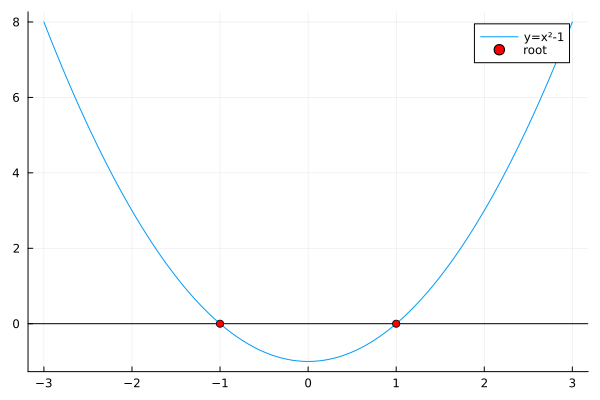

In [119]:
xs = -3:.01:3
plot(xs, [parabola(x, p) for x in xs], label = "y=x²-1", legend = :topright)
hline!([0], color = :black, label = "")
scatter!(roots, [0], color = :red, label = "root")

#### Additional Note

We can use `sol.retcode` to quickly view the behavior of the Newton Method.

For f(x) = x²-1, If our initial guess is x = .1:
Solution Output: 2.0
Return Code Output: Success

For f(x) = x²-1, If our initial guess is x = 0:
Solution Output: 0.0
Return Code Output: Unstable

For f(x) = 4-1/x², If our initial guess is x=10:
Solution Output: 10.0
Return Code Output: Unstable



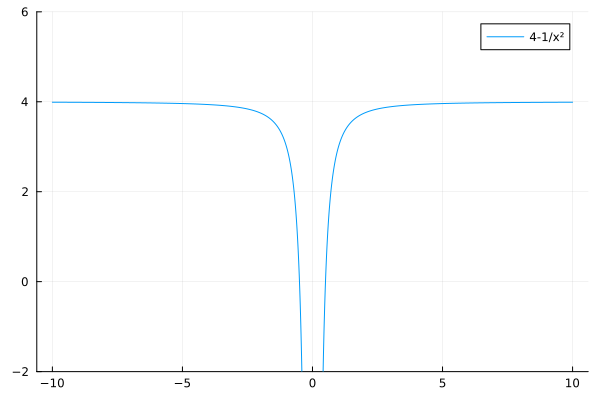

In [131]:
#For f(x) = x²-1, we would expect an initial guess of x = 2 to converge to the root x = 1
prob = NonlinearProblem(parabola, .1, p)
sol = solve(prob, NewtonRaphson())
println("For f(x) = x²-1, If our initial guess is x = .1:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

#For f(x) = x²-1, we would expect an initial guess of x = 0 to diverge since f'(0) = 0
prob = NonlinearProblem(parabola, 0, p)
sol = solve(prob, NewtonRaphson())
println("For f(x) = x²-1, If our initial guess is x = 0:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

#For f(x) = 4-1/x², we would expect a guess of x = 10 to blow up and diverge.
f(u, p) = p - (1/u[1]^2)
p = 4
prob = NonlinearProblem(f, 10, p)
sol = solve(prob, NewtonRaphson())
println("For f(x) = 4-1/x², If our initial guess is x=10:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

xs = -10:.01:10
plot(xs, [f(x, 4) for x in xs], label = "4-1/x²", ylims = (-2, 6))

#### Caution

For f(x) = x^20, If our initial guess is x=.5:
Solution Output: 0.38122726182060657
Return Code Output: Success



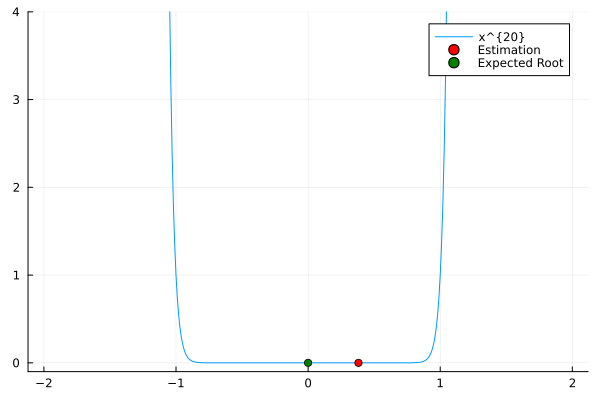

In [168]:
#For f(x) = x^30, we would expect the method to take a long time to get to the root.
f(u, p) = u[1]^30
prob = NonlinearProblem(f, .5, 0)
sol = solve(prob, NewtonRaphson())
println("For f(x) = x^20, If our initial guess is x=.5:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

xs = -2:.01:2
plot(xs, [f(x, 0) for x in xs], label = "x^{20}", ylims = (-.1, 4))
scatter!([sol.u], [f(sol.u, 0)], color=:red, label = "Estimation")
scatter!([0],[0], color=:green, label = "Expected Root")

This happens because the return code is based off the residual which we can use `sol.resid` to obtain. Since we know the true root, lets compare the residual with the error:

In [170]:
println("The Error is: $(sol.u-0)")
println("The Residual is: $(sol.resid)")

The Error is: 0.38122726182060657
The Residual is: 2.7259538129183167e-13


## 2.) Solving Systems of Non Linear Equations 

## 3.) Who is this software for?

## 4.) Brief Notes on Developmental Process

## 5.) Question

## 6.) Proposed Experiment